# CDS523 Case Study: Hong Kong Relative Humidity and AQHI

**Group:** GC  
**Students:** WU Songyuan (5550024); GUO Yuchuan (5539575)  
**Study period:** 1 January to 31 December 2025

## 1. Introduction

This notebook answers both phases of the case study:

1. Plot the **monthly mean of daily maximum relative humidity** for 18 districts.
2. Build an interactive Hong Kong map showing the **annual mean of daily maximum
   relative humidity** for 18 districts (blue) and the **annual mean of daily
   maximum AQHI** for 18 monitoring stations (red).

A daily maximum and a daily mean are different statistics. We first obtain the
maximum for each day, then average those daily maxima. Annual averages use the
365 daily values directly, rather than an unweighted average of 12 monthly means.

### How to run

- Use Python 3.11 or later with Jupyter Notebook or JupyterLab.
- Put the original **`data.zip` next to this notebook**. It must contain
  `district.csv`, `station.csv`, and `aqi/202501_Eng.csv` through `aqi/202512_Eng.csv`.
  The CSV files are read inside the ZIP; extraction is unnecessary.
- Install missing packages once, using the optional command below.
- Select **Restart Kernel and Run All Cells**. All weather data are downloaded
  again on each complete run. Phase 2 reuses Phase 1's in-memory humidity data.
- Internet access is required for the weather API and the map's JavaScript,
  marker icons, and OpenStreetMap tiles. Trust the notebook to view its HTML map.
- The notebook writes `phase1_monthly_humidity.png` and
  `phase2_hong_kong_map.html` to the working directory. It never modifies `data.zip`.

The submitted code is contained entirely in this notebook; no helper `.py` file
or previously generated output is required to run it.

## 2. Setup

If necessary, run the following command once in a notebook cell, then restart
the kernel:

```python
%pip install pandas numpy requests matplotlib folium
```

To install a local notebook interface from a terminal, use
`python -m pip install notebook`, then `python -m notebook`.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from io import StringIO
from html import escape
import calendar
import csv
import math
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import folium
from branca.element import Element
from IPython.display import display, Markdown

YEAR = 2025
DATA_ZIP = Path("data.zip")  # Change only this setting if the input is elsewhere.
OUTPUT_DIR = Path(".")
TIMEZONE = "Asia/Hong_Kong"
API_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARIABLE = "relative_humidity_2m_max"
START_DATE = f"{YEAR}-01-01"
END_DATE = f"{YEAR}-12-31"
EXPECTED_DATES = pd.date_range(START_DATE, END_DATE, freq="D")

if not DATA_ZIP.is_file():
    raise FileNotFoundError(
        "Place the original data.zip beside this notebook, or update DATA_ZIP."
    )
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = "{:.4f}".format
print(f"Input: {DATA_ZIP.name}; study days: {len(EXPECTED_DATES)}; timezone: {TIMEZONE}")

Input: data.zip; study days: 365; timezone: Asia/Hong_Kong


## 3. Input Data

`district.csv` describes administrative districts, while `station.csv` describes
AQHI monitoring stations. They are different sets of locations and are kept
separate. Station statistics will be matched to coordinates **by station name**,
not by row position. Map markers always use the original CSV coordinates, even
if the weather API returns a nearby model grid-cell coordinate.

In [2]:
def read_input_csv(member_name):
    '''Read one CSV directly from the supplied ZIP without changing it.'''
    with ZipFile(DATA_ZIP) as archive:
        with archive.open(member_name) as stream:
            return pd.read_csv(stream, dtype=str, keep_default_na=False)


def read_coordinates(member_name):
    table = read_input_csv(member_name)
    table["name"] = table["name"].str.strip()
    for column in ["latitude", "longitude"]:
        table[column] = pd.to_numeric(table[column].str.strip(), errors="raise")
    assert len(table) == 18 and table["name"].is_unique
    assert table["name"].ne("").all()
    assert table["latitude"].between(-90, 90).all()
    assert table["longitude"].between(-180, 180).all()
    return table.sort_values("name").reset_index(drop=True)


monthly_files = [f"aqi/{YEAR}{month:02d}_Eng.csv" for month in range(1, 13)]
with ZipFile(DATA_ZIP) as archive:
    required_files = ["district.csv", "station.csv", *monthly_files]
    missing_files = set(required_files) - set(archive.namelist())
    assert not missing_files, f"Missing input files: {sorted(missing_files)}"

districts = read_coordinates("district.csv")
stations = read_coordinates("station.csv")
district_names = districts["name"].tolist()
station_names = stations["name"].tolist()
print(f"Found all {len(required_files)} required CSV files.")
display(districts)
display(stations)

Found all 14 required CSV files.


,name,latitude,longitude
0,Central and Western,22.2867,114.1550
1,Eastern,22.2841,114.2241
2,Islands,22.2611,113.9461
3,Kowloon City,22.3282,114.1916
4,Kwai Tsing,22.3549,114.0840
5,Kwun Tong,22.3133,114.2258
6,North,22.4947,114.1381
7,Sai Kung,22.3814,114.2705
8,Sha Tin,22.3871,114.1953
9,Sham Shui Po,22.3307,114.1622


,name,latitude,longitude
0,Causeway Bay,22.2801,114.1851
1,Central,22.2818,114.1581
2,Central/Western,22.2849,114.1441
3,Eastern,22.2829,114.2194
4,Kwai Chung,22.3570,114.1294
5,Kwun Tong,22.3098,114.2315
6,Mong Kok,22.3226,114.1683
7,North,22.4969,114.1284
8,Sha Tin,22.3764,114.1846
9,Sham Shui Po,22.3304,114.1591


## 4. Phase 1: Relative Humidity

### 4.1 Retrieve daily maximum humidity

The request uses `daily=relative_humidity_2m_max`, not the daily mean or minimum.
The API's `daily.time` and humidity arrays are paired position by position.
We explicitly select **Asia/Hong_Kong (UTC+8)** so each daily maximum belongs to
a Hong Kong local day. The assignment's GMT metadata is an example; this notebook
states its local-day convention explicitly.

Each district has at most three attempts with a 30-second timeout per request.
HTTP errors, malformed responses, missing days, missing values, or invalid
humidity values trigger a retry. A final failure identifies the district and
stops execution. Missing humidity is **never filled with zero**.

The historical API supplies gridded weather reanalysis data, not a separate
physical weather station for every district. Nearby districts can therefore
have similar or identical series. This does not justify changing the data.

In [3]:
def parse_humidity(payload, district_name):
    '''Validate the response, then pair its dates and daily maximum values.'''
    if payload.get("error"):
        raise ValueError(payload.get("reason", "API returned an error"))
    daily = payload["daily"]
    if len(daily["time"]) != len(daily[WEATHER_VARIABLE]):
        raise ValueError("Dates and humidity values have different lengths")
    dates = pd.DatetimeIndex(pd.to_datetime(daily["time"]))
    humidity = pd.Series(daily[WEATHER_VARIABLE], dtype="float64")
    if not dates.equals(EXPECTED_DATES):
        raise ValueError("Response does not contain exactly the requested dates")
    if humidity.isna().any() or not humidity.between(0, 100).all():
        raise ValueError("Humidity is missing or outside 0-100 percent")
    if payload["daily_units"][WEATHER_VARIABLE] != "%":
        raise ValueError("Unexpected humidity unit")
    if payload.get("utc_offset_seconds") != 8 * 3600:
        raise ValueError("Expected Hong Kong local days (UTC+8)")
    return pd.DataFrame({
        "district": district_name,
        "date": dates,
        "day_max_rh": humidity.to_numpy(),
    })


def fetch_humidity(session, district):
    params = {
        "latitude": district.latitude,
        "longitude": district.longitude,
        "start_date": START_DATE,
        "end_date": END_DATE,
        "daily": WEATHER_VARIABLE,
        "timezone": TIMEZONE,
    }
    last_error = None
    for attempt in range(1, 4):
        try:
            response = session.get(API_URL, params=params, timeout=30)
            response.raise_for_status()
            payload = response.json()
            table = parse_humidity(payload, district.name)
            return table, payload
        except (requests.RequestException, ValueError, KeyError, TypeError) as error:
            last_error = error
            print(f"Retry information: {district.name}, attempt {attempt}/3: {error}")
            if attempt < 3:
                time.sleep(2 ** (attempt - 1))
    raise RuntimeError(
        f"Could not obtain valid humidity data for {district.name} after 3 attempts."
    ) from last_error


humidity_parts = []
weather_responses = {}  # Raw in-memory JSON supports independent verification.
with requests.Session() as session:
    for number, district in enumerate(districts.itertuples(index=False), start=1):
        table, payload = fetch_humidity(session, district)
        humidity_parts.append(table)
        weather_responses[district.name] = payload
        print(f"{number:02d}/18: {district.name}: {len(table)} valid daily maxima")
        time.sleep(0.2)

humidity_daily = pd.concat(humidity_parts, ignore_index=True)
assert len(humidity_daily) == 18 * len(EXPECTED_DATES)
assert not humidity_daily.duplicated(["district", "date"]).any()
display(humidity_daily.head())
print(f"Total humidity observations: {len(humidity_daily):,}")

01/18: Central and Western: 365 valid daily maxima


02/18: Eastern: 365 valid daily maxima


03/18: Islands: 365 valid daily maxima


04/18: Kowloon City: 365 valid daily maxima


05/18: Kwai Tsing: 365 valid daily maxima


06/18: Kwun Tong: 365 valid daily maxima


... (10 outputs left out)

17/18: Yau Tsim Mong: 365 valid daily maxima


18/18: Yuen Long: 365 valid daily maxima


,district,date,day_max_rh
0,Central and Western,2025-01-01,86.0000
1,Central and Western,2025-01-02,83.0000
2,Central and Western,2025-01-03,83.0000
3,Central and Western,2025-01-04,96.0000
4,Central and Western,2025-01-05,90.0000


Total humidity observations: 6,570


### 4.2 Calculate monthly and annual means

For district D and month M, the plotted value is the sum of daily maximum
humidity values in M divided by the number of days in M. For the annual map,
the sum over all 365 days is divided by 365. Months have different lengths,
so the annual mean is not calculated as an unweighted mean of monthly means.
Full precision is retained for calculation; rounding is only for display.

In [4]:
humidity_daily["month"] = humidity_daily["date"].dt.month
humidity_monthly = (
    humidity_daily.groupby(["month", "district"])["day_max_rh"]
    .mean().unstack("district")
    .reindex(index=range(1, 13), columns=district_names)
)
humidity_annual = (
    humidity_daily.groupby("district")["day_max_rh"]
    .mean().rename("annual_mean_day_max_rh")
)
district_summary = districts.merge(
    humidity_annual, left_on="name", right_index=True, validate="one_to_one"
)
assert humidity_monthly.shape == (12, 18)
assert humidity_monthly.notna().all().all()
assert len(district_summary) == 18
display(humidity_monthly.rename(index=lambda month: calendar.month_name[month]))
display(district_summary)

district,Central and Western,Eastern,Islands,Kowloon City,Kwai Tsing,Kwun Tong,North,Sai Kung,Sha Tin,Sham Shui Po,Southern,Tai Po,Tsuen Wan,Tuen Mun,Wan Chai,Wong Tai Sin,Yau Tsim Mong,Yuen Long
month,,,,,,,,,,,,,,,,,,
January,81.9355,81.8710,80.1935,81.8710,80.5806,81.8710,86.2903,81.5806,85.2581,81.8710,81.9677,86.2903,84.7097,82.3226,81.9355,81.8710,81.8710,81.1290
February,88.8929,88.8929,88.2143,88.8929,89.5357,88.8929,92.6071,88.2500,91.4286,88.8929,88.8929,92.6071,91.6071,87.8929,88.8929,88.8929,88.8929,90.0357
March,92.6774,92.6774,91.9032,92.6774,92.0000,92.6774,94.3871,92.0968,94.6129,92.6774,92.6774,94.3871,94.1935,90.0968,92.6774,92.6774,92.6774,91.0645
April,95.0000,94.9667,93.7667,94.9667,93.4333,94.9667,95.8000,93.7333,95.5667,94.9667,95.0000,95.8000,95.4667,92.1667,95.0000,94.9667,94.9667,93.6000
May,94.4194,94.4194,93.1935,94.4194,92.9677,94.4194,96.7097,94.0323,96.5484,94.4194,94.4194,96.7097,95.8065,91.2258,94.4194,94.4194,94.4194,93.4194
June,96.8000,96.8000,94.8333,96.8000,95.3333,96.8000,98.8333,95.8333,98.8667,96.8000,96.8000,98.8333,97.9667,92.2333,96.8000,96.8000,96.8000,95.7667
July,96.0968,96.0645,95.5806,96.0645,95.6774,96.0645,98.6129,95.5161,98.1613,96.0645,96.0968,98.6129,97.8387,92.7097,96.0968,96.0645,96.0645,96.0323
August,95.9677,95.9677,94.4516,95.9677,94.8065,95.9677,98.5484,95.7419,98.2581,95.9677,95.9677,98.5484,97.7097,92.0968,95.9677,95.9677,95.9677,95.4839
September,95.1333,95.1000,93.1667,95.1000,94.3333,95.1000,98.9667,94.9333,98.1667,95.1000,95.1333,98.9667,97.9667,93.0667,95.1333,95.1000,95.1000,95.4000


,name,latitude,longitude,annual_mean_day_max_rh
0,Central and Western,22.2867,114.1550,91.0192
1,Eastern,22.2841,114.2241,90.9890
2,Islands,22.2611,113.9461,89.7616
3,Kowloon City,22.3282,114.1916,90.9890
4,Kwai Tsing,22.3549,114.0840,89.9562
5,Kwun Tong,22.3133,114.2258,90.9890
6,North,22.4947,114.1381,94.1699
7,Sai Kung,22.3814,114.2705,90.5781
8,Sha Tin,22.3871,114.1953,93.6548
9,Sham Shui Po,22.3307,114.1622,90.9890


### 4.3 Monthly bar charts

Each panel contains the same 18 districts in alphabetical order. All panels use
the same 0-100% scale to allow comparisons between months.

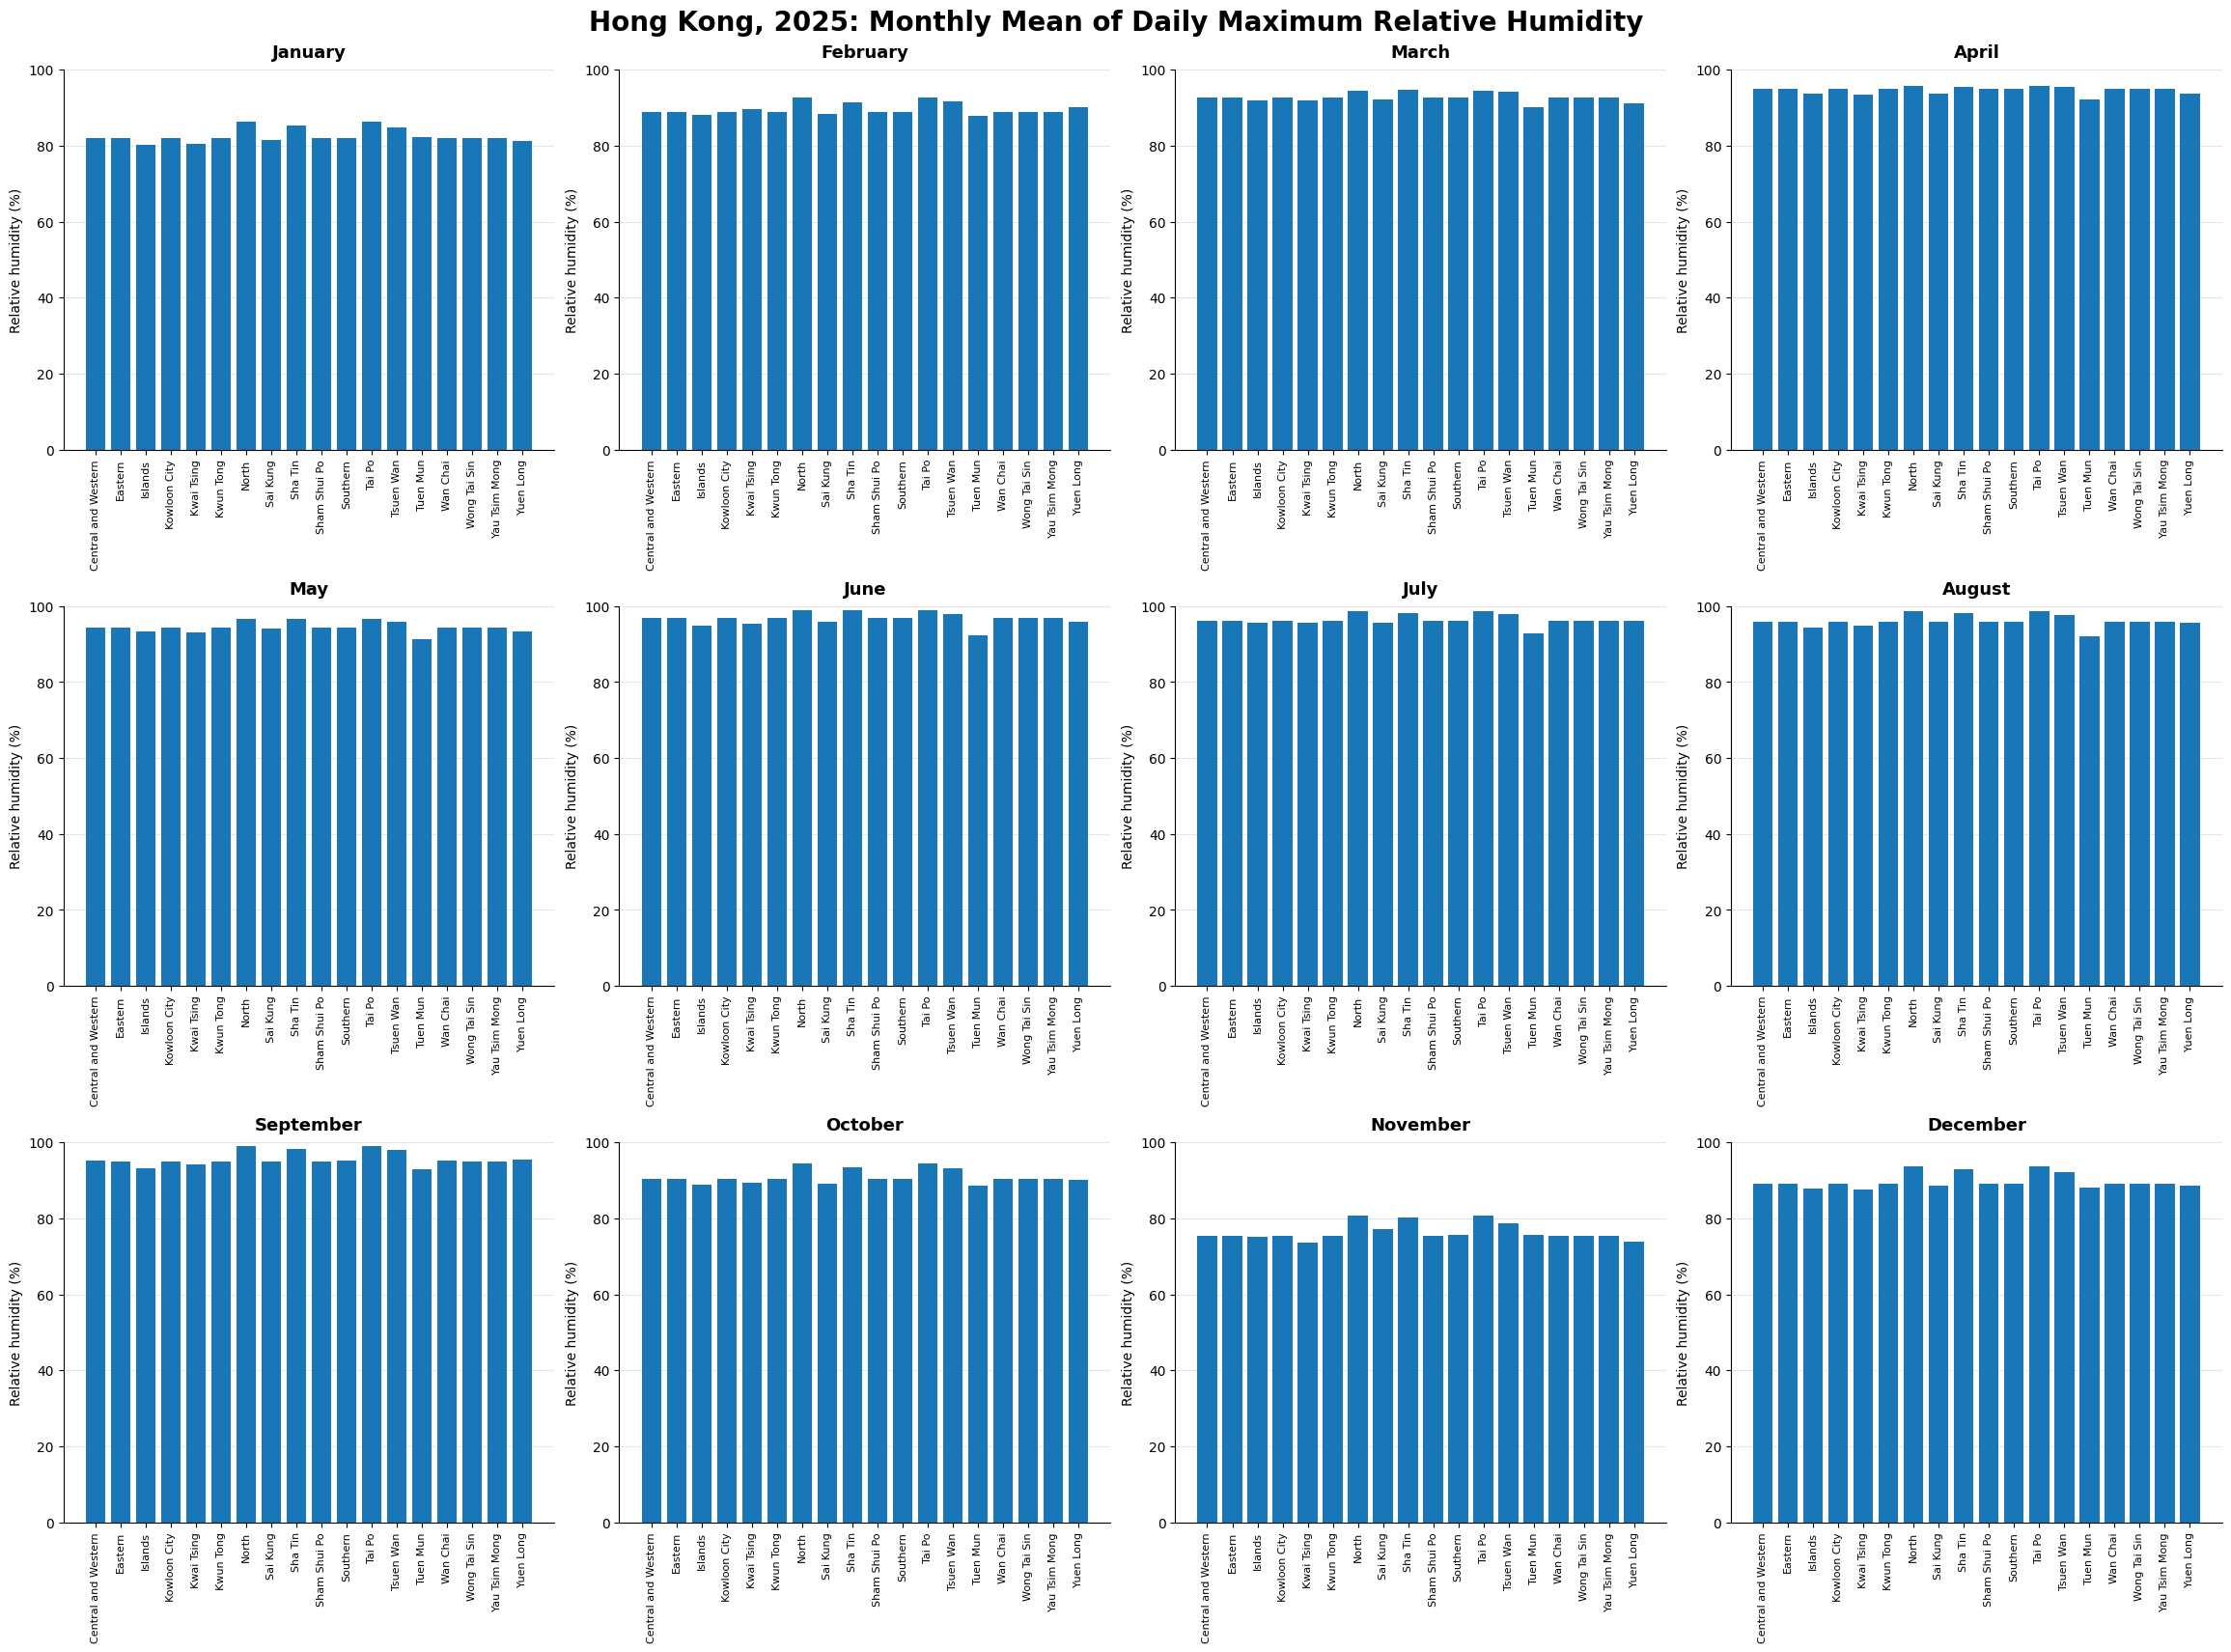

Saved phase1_monthly_humidity.png


In [5]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
fig, axes = plt.subplots(3, 4, figsize=(23, 17), layout="constrained")
fig.suptitle(
    "Hong Kong, 2025: Monthly Mean of Daily Maximum Relative Humidity",
    fontsize=20, fontweight="bold",
)
for month, ax in enumerate(axes.flat, start=1):
    ax.bar(district_names, humidity_monthly.loc[month], color="#1976b7", width=0.78)
    ax.set_title(calendar.month_name[month], fontsize=13, fontweight="bold", pad=9)
    ax.set_ylim(0, 100)
    ax.set_yticks(range(0, 101, 20))
    ax.set_ylabel("Relative humidity (%)", fontsize=10)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.grid(axis="y", color="#dce3eb", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

assert len(fig.axes) == 12
assert sum(len(ax.patches) for ax in fig.axes) == 216
chart_path = OUTPUT_DIR / "phase1_monthly_humidity.png"
fig.savefig(chart_path, dpi=180, facecolor="white")
plt.show()
print(f"Saved {chart_path.name}")

## 5. AQHI Processing

Each monthly file contains 24 hourly rows and one `Daily Max` row per day.
Blank dates are filled forward **inside each monthly file**. `Hour` remains a
label: `24` belongs to the date recorded in that file and is not shifted to the
next calendar day. Only the `Daily Max` rows are used for annual AQHI means.

Following the assignment, `+` and `*` are removed from AQHI values; therefore
`10+` becomes `10`, not `11`. Empty values and missing-data markers `-` and `-*`
become zero. This replacement is restricted to the 18 AQHI columns. It is the
assignment's preprocessing rule, not a general recommendation for missing data.
Dates and hour labels are never filled with zero. Unexpected tokens cause an
error rather than silently becoming zero.

In [6]:
def clean_aqhi_values(values):
    stripped = values.astype(str).str.strip()
    stripped = stripped.str.replace("+", "", regex=False)
    stripped = stripped.str.replace("*", "", regex=False).str.strip()
    stripped = stripped.replace({"": "0", "-": "0"})
    return pd.to_numeric(stripped, errors="raise")


aqhi_parts = []
raw_aqhi_parts = []
for month, filename in enumerate(monthly_files, start=1):
    raw = read_input_csv(filename)
    raw.columns = raw.columns.str.strip()
    assert len(raw.columns) == 20
    assert set(raw.columns) == {"Date", "Hour", *station_names}
    raw_aqhi_parts.append(raw[station_names].copy())
    raw["Date"] = raw["Date"].str.strip().replace("", pd.NA).ffill()
    raw["Date"] = pd.to_datetime(raw["Date"], format="%Y-%m-%d", errors="raise")
    raw["Hour"] = raw["Hour"].str.strip()
    assert raw["Date"].notna().all()
    assert raw["Date"].dt.year.eq(YEAR).all() and raw["Date"].dt.month.eq(month).all()
    for station_name in station_names:
        raw[station_name] = clean_aqhi_values(raw[station_name])
    aqhi_parts.append(raw)

aqhi_all = pd.concat(aqhi_parts, ignore_index=True)
raw_values = pd.concat(raw_aqhi_parts, ignore_index=True).stack().str.strip()
missing_audit = pd.Series({
    "Empty cells -> 0": int(raw_values.eq("").sum()),
    "Dash (-) -> 0": int(raw_values.eq("-").sum()),
    "Dash with asterisk (-*) -> 0": int(raw_values.eq("-*").sum()),
    "Cells containing + (symbol removed)": int(raw_values.str.contains("+", regex=False).sum()),
    "Cells containing * (symbol removed)": int(raw_values.str.contains("*", regex=False).sum()),
}, name="Cell count")
assert len(aqhi_all) == 365 * 25
assert not aqhi_all.duplicated(["Date", "Hour"]).any()
assert aqhi_all[station_names].notna().all().all()
assert aqhi_all[station_names].ge(0).all().all()
print("Cleaning audit (+ and * categories may overlap missing-marker categories):")
display(missing_audit.to_frame())
display(aqhi_all.head())

Cleaning audit (+ and * categories may overlap missing-marker categories):


,Cell count
Empty cells -> 0,162
Dash (-) -> 0,16
Dash with asterisk (-*) -> 0,155
Cells containing + (symbol removed),64
Cells containing * (symbol removed),3886


,Date,Hour,Central/Western,Southern,Eastern,Kwun Tong,Sham Shui Po,Kwai Chung,Tsuen Wan,Tseung Kwan O,Yuen Long,Tuen Mun,Tung Chung,Tai Po,Sha Tin,North,Tap Mun,Causeway Bay,Central,Mong Kok
0,2025-01-01,01,6,6,6,6,5,5,5,6,5,5,4,5,5,5,5,5,6,5
1,2025-01-01,02,7,6,5,5,5,5,5,5,5,5,5,5,6,5,5,5,6,5
2,2025-01-01,03,7,5,5,5,5,5,5,5,5,6,5,5,5,5,5,5,5,5
3,2025-01-01,04,6,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5
4,2025-01-01,05,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5


### 5.1 Annual mean of daily maximum AQHI

The supplied `Daily Max` values are used directly after cleaning. All 6,570
station-day maxima are also checked against maxima recomputed from the hourly
rows. The hourly rows are not averaged together with the `Daily Max` rows.

In [7]:
daily_aqhi = (
    aqhi_all.loc[aqhi_all["Hour"].eq("Daily Max"), ["Date", *station_names]]
    .set_index("Date").sort_index()
)
hourly_aqhi = aqhi_all.loc[~aqhi_all["Hour"].eq("Daily Max")].copy()
valid_hours = {f"{hour:02d}" for hour in range(1, 25)}
assert set(hourly_aqhi["Hour"]) == valid_hours
assert hourly_aqhi.groupby("Date").size().eq(24).all()
assert daily_aqhi.index.equals(EXPECTED_DATES)
hourly_maxima = hourly_aqhi.groupby("Date")[station_names].max().sort_index()
np.testing.assert_array_equal(daily_aqhi[station_names], hourly_maxima[station_names])

aqhi_annual = daily_aqhi.mean().rename("annual_mean_day_max_aqhi")
station_summary = stations.merge(
    aqhi_annual, left_on="name", right_index=True, validate="one_to_one"
)
assert len(station_summary) == 18
print(f"Validated {len(daily_aqhi)} daily rows against {len(hourly_aqhi):,} hourly rows.")
print(f"All {daily_aqhi.size:,} station-day maxima agree.")
display(station_summary)

Validated 365 daily rows against 8,760 hourly rows.
All 6,570 station-day maxima agree.


,name,latitude,longitude,annual_mean_day_max_aqhi
0,Causeway Bay,22.2801,114.1851,4.3260
1,Central,22.2818,114.1581,4.2411
2,Central/Western,22.2849,114.1441,4.1205
3,Eastern,22.2829,114.2194,4.1945
4,Kwai Chung,22.3570,114.1294,4.0603
5,Kwun Tong,22.3098,114.2315,4.0548
6,Mong Kok,22.3226,114.1683,4.3616
7,North,22.4969,114.1284,4.2493
8,Sha Tin,22.3764,114.1846,4.1068
9,Sham Shui Po,22.3304,114.1591,4.0959


## 6. Phase 2: Interactive Hong Kong Map

Blue markers represent districts and show annual mean daily maximum humidity
in percent. Red markers represent monitoring stations and show annual mean
daily maximum AQHI, which is an index without a percent unit. Each popup shows
the location name, year, and full metric description. Values are displayed to
two decimal places, while the underlying calculations retain full precision.

Use the layer controls to hide either group when nearby markers overlap.
The original district and station CSV coordinates are used separately. No
district-to-station equivalence or humidity-AQHI causal relationship is assumed.

In [8]:
hk_map = folium.Map(location=[22.36, 114.13], zoom_start=11, tiles="OpenStreetMap",
                    control_scale=True, width="100%", height=680)
district_layer = folium.FeatureGroup(name="Districts - relative humidity", show=True)
station_layer = folium.FeatureGroup(name="Stations - AQHI", show=True)
popup_audit = []


def add_metric_markers(table, layer, color, value_column, metric, unit):
    for row in table.to_dict("records"):
        value = row[value_column]
        formatted_value = f"{value:.2f}{unit}"
        popup_html = (
            '<div style="font-family:Arial,sans-serif;min-width:245px;line-height:1.5">'
            f'<h4 style="margin:0 0 8px">{escape(row["name"])}</h4>'
            f'<div><b>Year:</b> {YEAR}</div>'
            f'<div>{escape(metric)}:</div>'
            f'<div style="font-size:20px;font-weight:bold;margin-top:5px">'
            f'{formatted_value}</div></div>'
        )
        marker = folium.Marker(
            location=[row["latitude"], row["longitude"]],
            tooltip=f'{row["name"]} - {"humidity" if color == "blue" else "AQHI"}',
            popup=folium.Popup(popup_html, max_width=340),
            icon=folium.Icon(color=color, icon="info-sign"),
        )
        marker.add_to(layer)
        popup_audit.append({
            "name": row["name"], "color": color, "year": YEAR,
            "latitude": row["latitude"], "longitude": row["longitude"],
            "metric": metric, "value": value, "display_value": formatted_value,
            "popup_html": popup_html,
        })


add_metric_markers(
    district_summary, district_layer, "blue", "annual_mean_day_max_rh",
    "Annual mean of daily maximum relative humidity", "%",
)
add_metric_markers(
    station_summary, station_layer, "red", "annual_mean_day_max_aqhi",
    "Annual mean of daily maximum AQHI", "",
)
district_layer.add_to(hk_map)
station_layer.add_to(hk_map)
folium.LayerControl(collapsed=False).add_to(hk_map)
all_points = pd.concat([districts, stations], ignore_index=True)
hk_map.fit_bounds([
    [all_points["latitude"].min(), all_points["longitude"].min()],
    [all_points["latitude"].max(), all_points["longitude"].max()],
], padding=(35, 35))

legend = '''
<aside aria-label="Map legend" style="position:absolute;top:15px;left:60px;
 z-index:1000;background:white;border:1px solid #bcc8d4;border-radius:6px;
 padding:12px 16px;font:13px Arial,sans-serif;box-shadow:0 2px 7px #0002">
 <b>Hong Kong | 2025</b><br>
 <span style="color:#2187c2">&#9679;</span> Districts: mean daily maximum RH (%)<br>
 <span style="color:#d63e2a">&#9679;</span> Stations: mean daily maximum AQHI<br>
 <small>Click a marker for its annual value.</small>
</aside>
'''
hk_map.get_root().html.add_child(Element(legend))
def marker_count(layer):
    # Rendering may add helper objects; count only actual markers.
    return sum(isinstance(child, folium.Marker) for child in layer._children.values())


assert marker_count(district_layer) == 18
assert marker_count(station_layer) == 18
map_path = OUTPUT_DIR / "phase2_hong_kong_map.html"
hk_map.save(str(map_path))
print(f"Saved {map_path.name}: 18 blue markers + 18 red markers")
display(hk_map)

Saved phase2_hong_kong_map.html: 18 blue markers + 18 red markers


## 7. Validation

These checks test the statistical definitions, special-token handling, date
coverage, chart size, marker counts, and the mapping of statistics to coordinates.
The example numerical checks use independent Python sums of raw API arrays and
CSV daily maxima, rather than repeating the same pandas aggregation.

In [9]:
checks = []


def record_check(label, condition):
    if not bool(condition):
        raise AssertionError(label)
    checks.append({"Check": label, "Result": "PASS"})


# Check the cleaning rule independently against fixed expected answers.
examples = pd.Series(["10+", "5*", "", "-", "-*", " 7* "])
record_check("AQHI special tokens", clean_aqhi_values(examples).tolist() == [10, 5, 0, 0, 0, 7])

# Independently calculate a district's January and full-year means from JSON lists.
example_district = district_names[0]
raw_daily = weather_responses[example_district]["daily"]
jan_values = [value for date, value in zip(raw_daily["time"], raw_daily[WEATHER_VARIABLE])
              if date.startswith(f"{YEAR}-01-")]
manual_month_mean = math.fsum(jan_values) / len(jan_values)
manual_year_mean = math.fsum(raw_daily[WEATHER_VARIABLE]) / len(EXPECTED_DATES)
record_check("Independent January humidity mean", math.isclose(
    manual_month_mean, humidity_monthly.loc[1, example_district], abs_tol=1e-10))
record_check("Independent annual humidity mean", math.isclose(
    manual_year_mean, humidity_annual.loc[example_district], abs_tol=1e-10))

# Independently read one station's Daily Max cells using the standard-library CSV reader.
example_station = station_names[0]
manual_daily_aqhi = []
with ZipFile(DATA_ZIP) as archive:
    for filename in monthly_files:
        text = archive.read(filename).decode("utf-8-sig")
        for row in csv.DictReader(StringIO(text)):
            if row["Hour"].strip() == "Daily Max":
                token = row[example_station].strip().replace("+", "").replace("*", "").strip()
                manual_daily_aqhi.append(float(token) if token not in ("", "-") else 0.0)
record_check("Independent annual AQHI mean", len(manual_daily_aqhi) == 365 and math.isclose(
    math.fsum(manual_daily_aqhi) / 365, aqhi_annual.loc[example_station], abs_tol=1e-10))

# Weighting monthly means by their actual day counts must reproduce annual means.
month_days = np.array([calendar.monthrange(YEAR, month)[1] for month in range(1, 13)])
weighted_annual = np.average(humidity_monthly.to_numpy(), axis=0, weights=month_days)
record_check("Annual humidity respects month lengths", np.allclose(
    weighted_annual, humidity_annual.reindex(district_names).to_numpy(), atol=1e-10, rtol=0))
record_check("18 districts, 365 complete days each", len(humidity_daily) == 6570 and
             humidity_daily.groupby("district").size().eq(365).all())
record_check("12 x 18 monthly humidity means", humidity_monthly.shape == (12, 18))
record_check("365 daily AQHI rows and 8760 hourly rows",
             len(daily_aqhi) == 365 and len(hourly_aqhi) == 8760)
record_check("All 6570 AQHI daily maxima equal hourly maxima",
             np.array_equal(daily_aqhi[station_names], hourly_maxima[station_names]))
record_check("Dates and hour labels are retained", aqhi_all["Date"].notna().all() and
             set(aqhi_all["Hour"]) == valid_hours | {"Daily Max"})
record_check("12 chart panels and 216 bars", len(fig.axes) == 12 and
             sum(len(ax.patches) for ax in fig.axes) == 216)
record_check("18 blue and 18 red markers", marker_count(district_layer) == 18 and
             marker_count(station_layer) == 18)

# Check all popup contents and original coordinates against the summary tables.
popup_ok = True
for item in popup_audit:
    source = district_summary if item["color"] == "blue" else station_summary
    column = "annual_mean_day_max_rh" if item["color"] == "blue" else "annual_mean_day_max_aqhi"
    expected_row = source.set_index("name").loc[item["name"]]
    expected_unit = "%" if item["color"] == "blue" else ""
    popup_ok = popup_ok and (
        item["latitude"] == expected_row["latitude"] and
        item["longitude"] == expected_row["longitude"] and
        item["display_value"] == f'{expected_row[column]:.2f}{expected_unit}' and
        str(YEAR) in item["popup_html"] and item["metric"] in item["popup_html"] and
        escape(item["name"]) in item["popup_html"]
    )
record_check("All 36 popup values, labels and coordinates", popup_ok and len(popup_audit) == 36)
record_check("PNG and HTML outputs exist", chart_path.is_file() and map_path.is_file())

validation_results = pd.DataFrame(checks)
display(validation_results)
print(f"All {len(checks)} validation checks passed.")

,Check,Result
0,AQHI special tokens,PASS
1,Independent January humidity mean,PASS
2,Independent annual humidity mean,PASS
3,Independent annual AQHI mean,PASS
4,Annual humidity respects month lengths,PASS
5,"18 districts, 365 complete days each",PASS
6,12 x 18 monthly humidity means,PASS
7,365 daily AQHI rows and 8760 hourly rows,PASS
8,All 6570 AQHI daily maxima equal hourly maxima,PASS
9,Dates and hour labels are retained,PASS


All 14 validation checks passed.


## 8. Results and Limitations

The following observations are generated from the computed values. Extremes
refer to the supplied locations and the chosen daily-maximum statistics; they
are not evidence that humidity causes changes in AQHI. The assignment's AQHI
rule maps `10+` to `10` and missing cells to zero, which should be considered
when interpreting the index. Weather reanalysis and map tiles are supplied by
external services and may be updated over time.

In [10]:
wettest = humidity_annual.idxmax()
driest = humidity_annual.idxmin()
highest_aqhi = aqhi_annual.idxmax()
lowest_aqhi = aqhi_annual.idxmin()
month_averages = humidity_monthly.mean(axis=1)
highest_month = int(month_averages.idxmax())
lowest_month = int(month_averages.idxmin())

display(Markdown(f'''
### Observations from the 2025 data

- **Humidity, highest annual mean daily maximum:** {wettest}, {humidity_annual[wettest]:.2f}%.
- **Humidity, lowest annual mean daily maximum:** {driest}, {humidity_annual[driest]:.2f}%.
- **Across the 18 district values**, the highest monthly average is
  {calendar.month_name[highest_month]} ({month_averages[highest_month]:.2f}%), and the
  lowest is {calendar.month_name[lowest_month]} ({month_averages[lowest_month]:.2f}%).
  This is an unweighted comparison of the 18 supplied district locations.
- **AQHI, highest annual mean daily maximum:** {highest_aqhi}, {aqhi_annual[highest_aqhi]:.2f}.
- **AQHI, lowest annual mean daily maximum:** {lowest_aqhi}, {aqhi_annual[lowest_aqhi]:.2f}.
- **Validation:** all {len(checks)} programmed checks passed; the map contains
  18 district markers and 18 monitoring-station markers.

If an extreme is shared, the name above is the first matching location in
alphabetical order; the full summary tables retain every location.
'''))


### Observations from the 2025 data

- **Humidity, highest annual mean daily maximum:** North, 94.17%.
- **Humidity, lowest annual mean daily maximum:** Tuen Mun, 88.87%.
- **Across the 18 district values**, the highest monthly average is
  June (96.65%), and the
  lowest is November (76.40%).
  This is an unweighted comparison of the 18 supplied district locations.
- **AQHI, highest annual mean daily maximum:** Tuen Mun, 4.55.
- **AQHI, lowest annual mean daily maximum:** Tsuen Wan, 3.81.
- **Validation:** all 14 programmed checks passed; the map contains
  18 district markers and 18 monitoring-station markers.

If an extreme is shared, the name above is the first matching location in
alphabetical order; the full summary tables retain every location.


### Sources

- CDS523 *Case Study Assignment*: definitions, required outputs, and cleaning rules.
- Supplied `data.zip`: district coordinates, monitoring-station coordinates,
  and January-December 2025 AQHI CSV files.
- [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api):
  daily maximum relative humidity at 2 metres and local-day timezone configuration.
- [Folium documentation](https://python-visualization.github.io/folium/): interactive mapping.
- OpenStreetMap contributors: map tiles, with attribution retained on the map.